# Kickstarter: benchmarking a launch plan and predicting funding outcomes

**DATA3125 · 63,075 campaigns launched in 2024–2026**

Can historical Kickstarter campaigns help an early-stage founder benchmark a
launch plan? This notebook answers four questions using the verified cleaned
CSV, with no raw downloads required:

1. How do success rates differ by category and country?
2. How are funding goal and duration associated with success?
3. How do success rates vary by launch month and year?
4. Can five launch-plan features predict whether a campaign reaches its goal?

The cohort includes recorded successful/failed campaigns with a deadline and
outcome through October 1, 2026 UTC. It is an observed Web Robots scrape
cohort, **not all Kickstarter launches**. Rates are associations, not estimates
of the effect of changing a launch plan. The prep notebook documents sampling,
deduplication, eligibility, and feature provenance.

In [1]:
from pathlib import Path
import sys, json, hashlib
from zipfile import ZipFile
import numpy as np
import pandas as pd
from IPython.display import display

ROOT = Path.cwd()
if not (ROOT / 'sources.json').is_file():
    ROOT = ROOT.parent
assert (ROOT / 'sources.json').is_file(), 'Run from the project root or code/.'
sys.path.insert(0, str(ROOT / 'code'))

import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
from sklearn.base import clone
from kickstarter import (FEATURES, FIGURES, GOAL_BINS, GOAL_LABELS,
                         DURATION_BINS, DURATION_LABELS,
                         load_cleaned, make_models, evaluate, score_campaign)
plt.rcParams.update({'font.family':'DejaVu Sans', 'font.size':11,
                     'text.parse_math':False, 'axes.titlesize':14, 'axes.labelsize':11,
                     'axes.spines.top':False, 'axes.spines.right':False,
                     'figure.dpi':110, 'savefig.dpi':180})
FIGURE_DIR = ROOT/'visualizations'
FIGURE_DIR.mkdir(exist_ok=True)

def save_figure(fig, filename):
    fig.savefig(FIGURE_DIR/filename, dpi=180, facecolor='white', bbox_inches='tight',
                metadata={'Software':'DATA3125 Kickstarter analysis'})
    plt.show()
    plt.close(fig)

def summary(frame, group):
    table = frame.groupby(group, observed=True).agg(campaigns=('success','size'), successful=('success','sum'))
    table['success_rate_pct'] = (100*table['successful']/table['campaigns']).round(1)
    return table

def horizontal_rates(table, title, ylabel, filename, invert=False):
    fig, ax = plt.subplots(figsize=(10.5, max(4, 0.38*len(table)+1.8)), layout='constrained')
    bars = ax.barh(table.index.astype(str), table['success_rate_pct'], color='#28628e')
    ax.bar_label(bars, labels=[f'{r:.1f}%  (n={n:,})' for r,n in zip(table.success_rate_pct,table.campaigns)], padding=4, fontsize=9)
    ax.set(xlim=(0,100), title=title, xlabel='Campaigns reaching funding goal (%)', ylabel=ylabel)
    ax.set_xticks(range(0,101,20))
    ax.grid(axis='x', alpha=.18)
    ax.set_axisbelow(True)
    if invert: ax.invert_yaxis()
    save_figure(fig, filename)

campaigns = load_cleaned()
assert len(campaigns) == 63075
assert campaigns['id'].is_unique
print(f'{len(campaigns):,} unique campaigns; {campaigns.success.sum():,} successful; {(campaigns.success==0).sum():,} failed.')
display(campaigns.groupby('launch_year').success.agg(campaigns='size', successful='sum'))

63,075 unique campaigns; 44,658 successful; 18,417 failed.


,campaigns,successful
launch_year,,
2024,20581,13734
2025,25706,18115
2026,16788,12809


## Question 1 · Category and country

Compute campaign counts alongside rates. The country chart uses the ten
highest-volume markets, selected by sample size rather than by success rate.
The exported charts include counts so high rates in small groups stay visible.

,campaigns,successful,success_rate_pct
main_category,,,
Games,14390,12152,84.4
Publishing,8256,6024,73.0
Film & Video,6435,3297,51.2
Technology,6262,3521,56.2
Comics,6004,5592,93.1
Design,5617,4498,80.1
Art,4523,3362,74.3
Music,3170,2142,67.6
Fashion,2658,1441,54.2


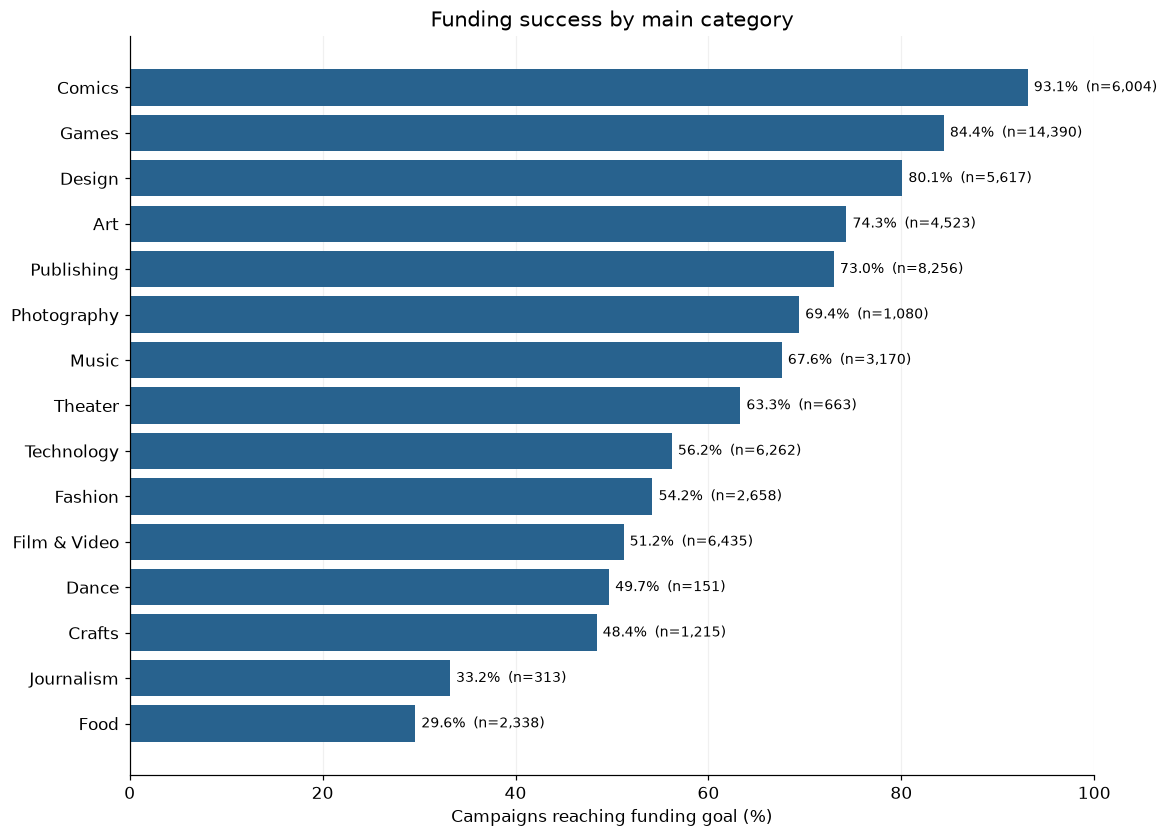

In [2]:
category_summary = summary(campaigns, 'main_category')
display(category_summary.sort_values('campaigns', ascending=False))
horizontal_rates(category_summary.sort_values('success_rate_pct'),
                 'Funding success by main category', '', FIGURES[0])

Comics reached its funding goal in **93.1%** of eligible campaigns, compared
with **84.4%** for Games. A founder should compare a launch plan with similar
categories, rather than assuming the overall rate applies to every product.
Category differences can reflect audience, goal size, and who appears in the
scrapes; they do not show that changing categories causes success.

,campaigns,successful,success_rate_pct
country,,,
US,33948,23879,70.3
GB,7260,5409,74.5
CA,3292,2289,69.5
HK,2773,2512,90.6
DE,1924,1125,58.5
ES,1884,1327,70.4
AU,1758,1220,69.4
IT,1679,1006,59.9
FR,1557,1086,69.7


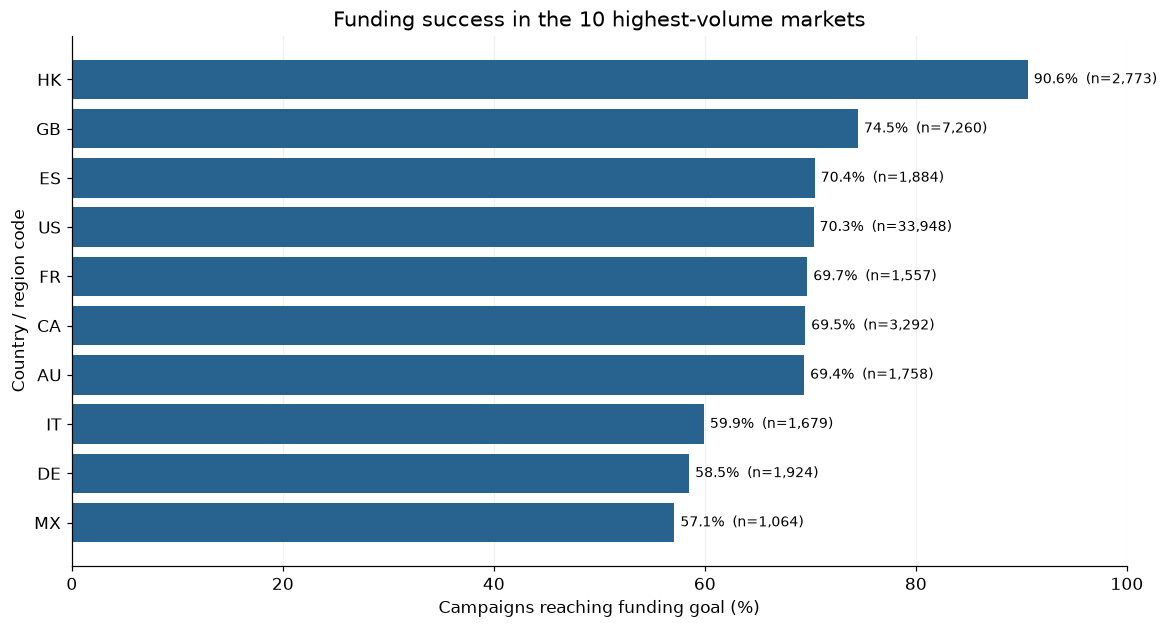

In [3]:
country_summary = summary(campaigns, 'country')
display(country_summary.nlargest(10, 'campaigns'))
horizontal_rates(country_summary.nlargest(10, 'campaigns').sort_values('success_rate_pct'),
                 'Funding success in the 10 highest-volume markets',
                 'Country / region code', FIGURES[1])

Among the ten highest-volume markets, **Hong Kong (HK)** has the highest
observed success rate: **90.6%**, from **2,773 campaigns**. The **US** rate is
**70.3%**, from **33,948 campaigns**. These are different observed campaign
mixes, not evidence that moving a founder to another country improves their
odds. Country and category provide useful starting benchmarks.

## Question 2 · Funding goal and duration

Use the existing USD-goal bins, **left-inclusive / right-exclusive**, and
existing duration bins, **right-inclusive**: up to 14, >14–30, >30–45, >45–60,
and >60 days. Duration retains fractional days; a 30.1-day campaign belongs
to >30–45. The $10,000–<$25,000 cohort includes $10,000 and excludes $25,000.

,campaigns,successful,success_rate_pct
goal_band,,,
"Under $1,000",17185,15345,89.3
"$1,000–<$5,000",20141,15495,76.9
"$5,000–<$10,000",9812,6396,65.2
"$10,000–<$25,000",9359,5201,55.6
"$25,000–<$50,000",3762,1440,38.3
"$50,000+",2816,781,27.7


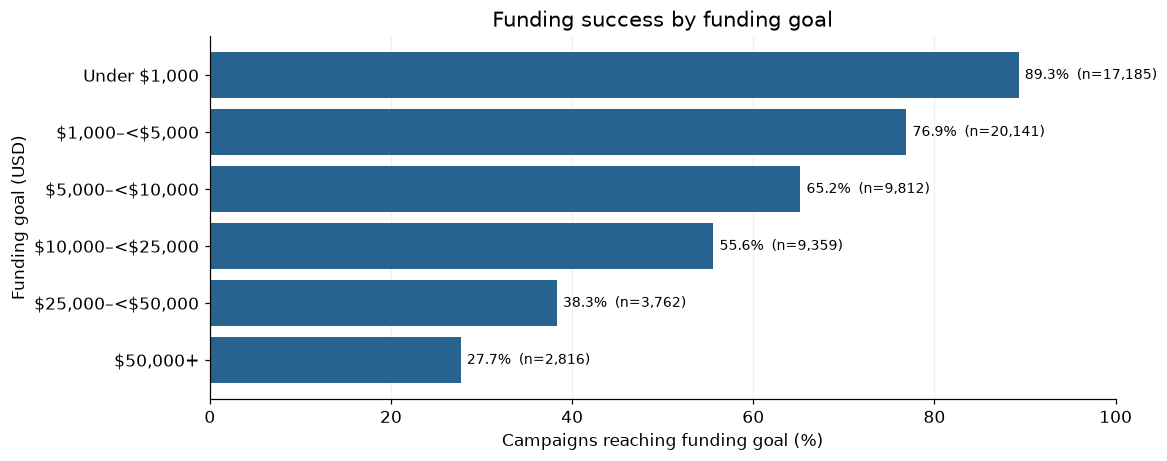

In [4]:
campaigns['goal_band'] = pd.cut(campaigns['funding_goal_usd'], GOAL_BINS, labels=GOAL_LABELS, right=False)
campaigns['duration_band'] = pd.cut(campaigns['duration_days'], DURATION_BINS, labels=DURATION_LABELS)
goal_summary = summary(campaigns, 'goal_band')
display(goal_summary)
horizontal_rates(goal_summary, 'Funding success by funding goal',
                 'Funding goal (USD)', FIGURES[2], invert=True)

Campaigns seeking **under $1,000** succeeded **89.3%** of the time, compared
with **27.7%** for campaigns seeking **$50,000 or more**. Higher goals can be
harder to reach, but this observational comparison also mixes categories,
countries, and campaign characteristics. It is a benchmark, not a causal
estimate of lowering a funding goal.

,campaigns,successful,success_rate_pct
duration_band,,,
Up to 14 days,4733,4220,89.2
>14–30 days,36799,27833,75.6
>30–45 days,12677,9151,72.2
>45–60 days,8104,3195,39.4
>60 days,762,259,34.0


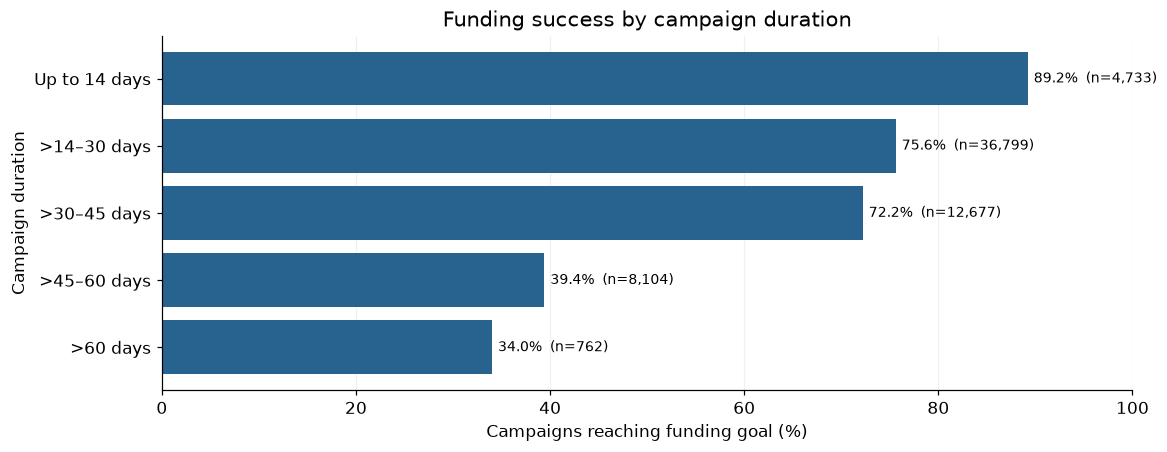

In [5]:
duration_summary = summary(campaigns, 'duration_band')
display(duration_summary)
horizontal_rates(duration_summary, 'Funding success by campaign duration',
                 'Campaign duration', FIGURES[3], invert=True)

Across all funding goals, campaigns lasting **up to 14 days** have the highest
observed success rate. Before recommending a shorter launch, compare within
a funding range: goal size and campaign mix can change that ranking.

,campaigns,successful,success_rate_pct
duration_band,,,
Up to 14 days,152,94,61.8
>14–30 days,5095,3082,60.5
>30–45 days,2416,1595,66.0
>45–60 days,1552,394,25.4
>60 days,144,36,25.0


campaigns  successful  success_rate_pct
cohort                 duration                                              
All funding goals      Up to 14 days       4733        4220              89.2
                       >30–45 days        12677        9151              72.2
$10,000–<$25,000 goals Up to 14 days        152          94              61.8
                       >30–45 days         2416        1595              66.0

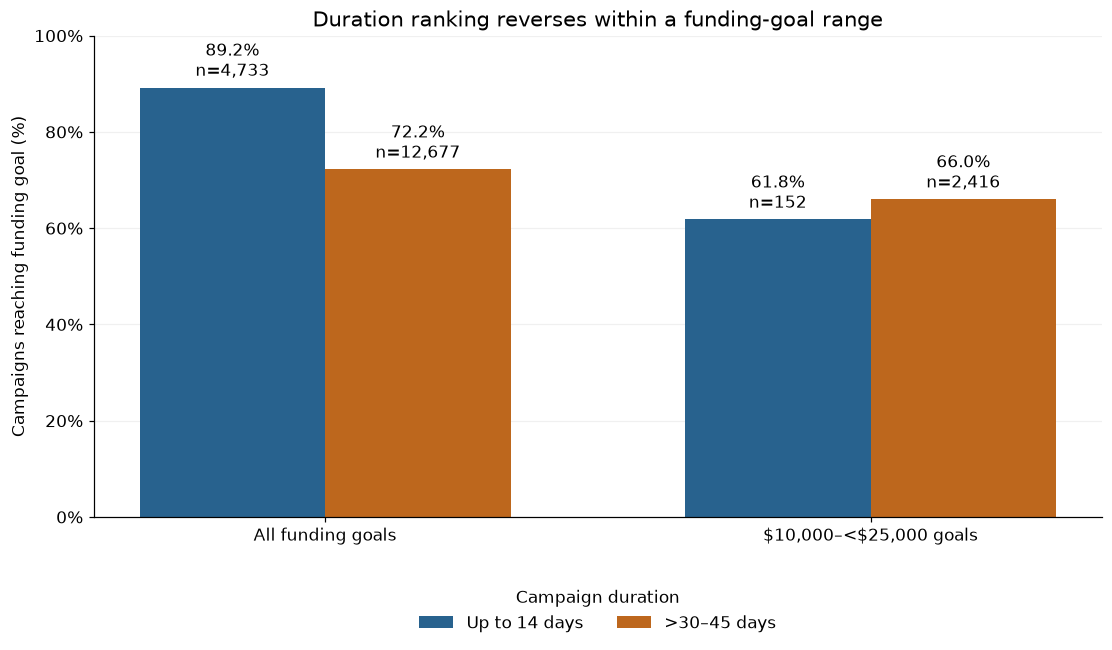

In [6]:
similar_goals = campaigns.loc[campaigns.funding_goal_usd.ge(10000) & campaigns.funding_goal_usd.lt(25000)]
duration_at_similar_goals = summary(similar_goals, 'duration_band')
display(duration_at_similar_goals)
selected_durations = ['Up to 14 days','>30–45 days']
comparison = pd.concat({
    'All funding goals': duration_summary.loc[selected_durations],
    '$10,000–<$25,000 goals': duration_at_similar_goals.loc[selected_durations],
}, names=['cohort','duration'])
display(comparison)
fig, ax = plt.subplots(figsize=(10,5.8), layout='constrained')
x = np.arange(2)
width = .34
colors = ['#28628e','#bd671d']
for i, duration in enumerate(selected_durations):
    rows = comparison.xs(duration, level='duration')
    bars = ax.bar(x + (i-.5)*width, rows.success_rate_pct, width,
                  label=duration, color=colors[i])
    ax.bar_label(bars, labels=[f'{r:.1f}%\nn={n:,}' for r,n in zip(rows.success_rate_pct,rows.campaigns)], padding=4, fontsize=11)
ax.set(ylim=(0,100), xticks=x, xticklabels=['All funding goals','$10,000–<$25,000 goals'],
       ylabel='Campaigns reaching funding goal (%)',
       title='Duration ranking reverses within a funding-goal range')
ax.yaxis.set_major_formatter(PercentFormatter(xmax=100, decimals=0))
ax.legend(title='Campaign duration', loc='upper center', bbox_to_anchor=(.5,-.12), ncols=2, frameon=False)
ax.grid(axis='y',alpha=.18)
ax.set_axisbelow(True)
save_figure(fig, FIGURES[4])

**The ranking reverses in this observed subset.** Across all goals, up-to-14-day
campaigns succeeded **89.2% (n=4,733)** versus **72.2% (n=12,677)** for >30–45
days. Within $10,000–<$25,000 goals, the rates are **61.8% (n=152)** versus
**66.0% (n=2,416)**. The shortest group in the narrower cohort is much smaller,
so its rate deserves particular caution. This is an association after one
restriction, not proof that extending a campaign improves its outcome. Other
campaign differences remain uncontrolled.

## Question 3 · Launch month and year

Only eligible finished campaigns contribute. Late-2026 points are strongly
selected by the October 1 deadline/outcome cutoff. Missing months mean no
eligible observations, not a 0% success rate.

campaigns                 success_rate_pct            
launch_year       2024    2025    2026             2024  2025  2026
launch_month                                                       
1               1500.0  1920.0  2073.0             65.4  66.8  71.6
2               1608.0  2025.0  2222.0             69.5  70.3  77.5
3               1687.0  2029.0  2552.0             67.4  71.4  73.8
4               1709.0  2068.0  2246.0             66.7  69.9  73.7
5               1780.0  2203.0  2095.0             66.2  69.7  74.9
6               1619.0  2322.0  2057.0             65.2  70.3  75.7
7               1698.0  2223.0  1908.0             66.2  69.4  78.4
8               1597.0  2054.0  1297.0             65.4  71.6  86.4
9               1954.0  2437.0   338.0             68.8  73.0  95.0
10              2285.0  2785.0     NaN             71.3  74.6   NaN
11              1878.0  2196.0     NaN             64.8  70.8   NaN
12              1266.0  1444.0     NaN             60.6  63.8   NaN

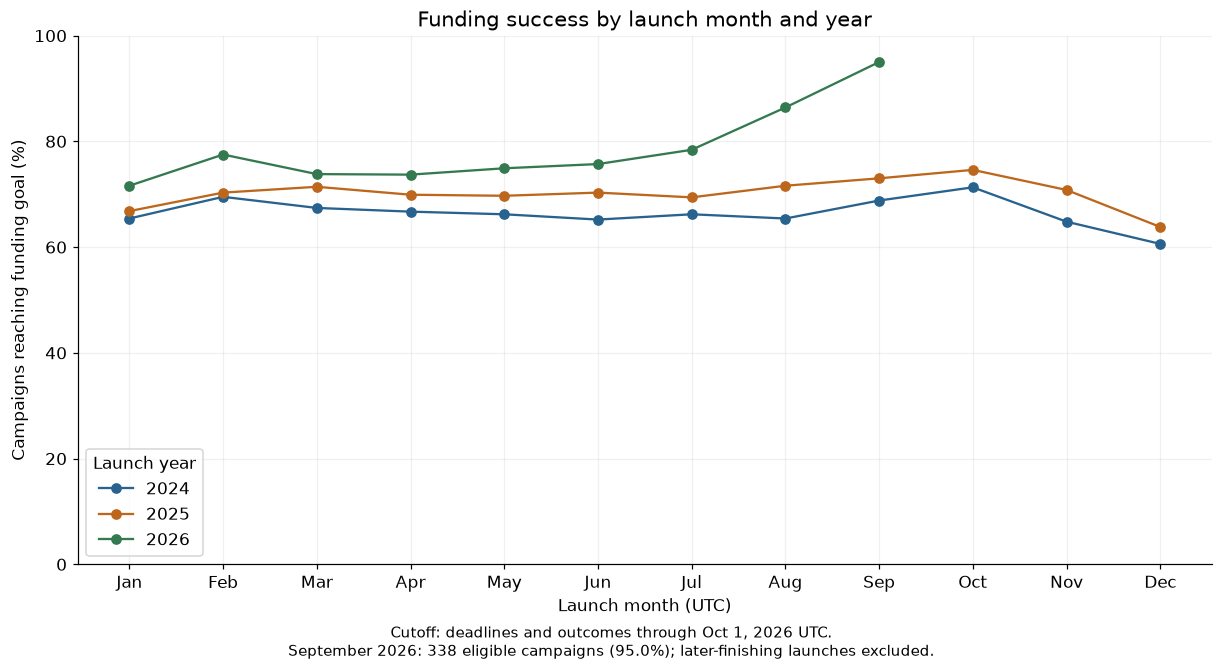

In [7]:
timing_summary = summary(campaigns, ['launch_year','launch_month'])
display(timing_summary[['campaigns','success_rate_pct']].unstack('launch_year'))
monthly_rates = timing_summary.success_rate_pct.unstack('launch_year').reindex(range(1,13))
fig, ax = plt.subplots(figsize=(11,6), layout='constrained')
for year, color in zip([2024,2025,2026], ['#28628e','#bd671d','#34794f']):
    ax.plot(monthly_rates.index, monthly_rates[year], marker='o', label=str(year), color=color)
ax.set(ylim=(0,100), xticks=range(1,13),
       xticklabels='Jan Feb Mar Apr May Jun Jul Aug Sep Oct Nov Dec'.split(),
       xlabel='Launch month (UTC)', ylabel='Campaigns reaching funding goal (%)',
       title='Funding success by launch month and year')
ax.legend(title='Launch year', loc='lower left')
ax.grid(alpha=.18)
fig.supxlabel('Cutoff: deadlines and outcomes through Oct 1, 2026 UTC.\nSeptember 2026: 338 eligible campaigns (95.0%); later-finishing launches excluded.', fontsize=10)
save_figure(fig, FIGURES[5])

For March launches, observed success rose from **67.4% (2024)** to **71.4%
(2025)** and **73.8% (2026)**. September 2026 reached **95.0%**, but includes
only **338 eligible campaigns**, compared with **2,437** in September 2025.
The October 1 cutoff excludes later-finishing launches, so the September 2026
value is a selected subset rather than a complete monthly success rate. These
series do not establish an ideal causal launch month.

## Question 4 · Five-input prediction and complete evaluation

**Predictors only:** USD goal, duration, launch month, main category, country.
The ID, year, timestamps, and target stay out of `X`. Numeric features are
standardized; categorical features (including month) are one-hot encoded with
unknown values ignored. Each pipeline fits its own preprocessing only on the
training rows passed to `.fit()`.

Preserve the existing **launch-year split**: fit on 2024, compare fixed Logistic
Regression and depth-5 Decision Tree on 2025, select using 2025 accuracy,
then refit the fixed pipelines on 2024–2025 and evaluate once on 2026.
There is no 2026 tuning. The always-success baseline predicts class 1.

All precision, recall and F1 values below measure **failure (class 0)**.
Accuracy measures all campaigns. Confusion matrices use rows = **actual**,
columns = **predicted**, in class order **[0 failed, 1 successful]**.
Baseline failure precision is reported as 0 by `zero_division=0` because it
never predicts failure; its failure recall and F1 are also 0.

In [8]:
X = campaigns[FEATURES]
y = campaigns['success']
fit_rows = campaigns.launch_year.eq(2024)
validation_rows = campaigns.launch_year.eq(2025)
train_rows = campaigns.launch_year.isin([2024,2025])
test_rows = campaigns.launch_year.eq(2026)
assert set(X.columns) == set(FEATURES) and len(X.columns) == 5
assert not set(['success','launch_year','pledged','backers_count','state','outcome_utc']) & set(X.columns)
print('2024 fit:', fit_rows.sum(), '| 2025 validation:', validation_rows.sum(), '| 2026 final evaluation:', test_rows.sum())
models = make_models()
validation_results = {'Always success':evaluate(y[validation_rows], np.ones(validation_rows.sum(), dtype=int))}
for name, model in models.items():
    model.fit(X[fit_rows], y[fit_rows])
    validation_results[name] = evaluate(y[validation_rows], model.predict(X[validation_rows]))
selected_name = max(models, key=lambda name:validation_results[name]['accuracy'])
assert selected_name == 'Decision Tree'

def show_metrics(results):
    table = pd.DataFrame({name:{k:v for k,v in result.items() if k != 'confusion_matrix'} for name,result in results.items()}).T
    table.columns = ['Accuracy (all)','Precision (failure 0)','Recall (failure 0)','F1 (failure 0)']
    display(table.map(lambda value: f'{value:.1%}'))
    for name, result in results.items():
        print(name)
        display(pd.DataFrame(result['confusion_matrix'],
            index=pd.Index(['0 Failed','1 Successful'], name='Actual'),
            columns=pd.Index(['0 Failed','1 Successful'], name='Predicted')))

print('2025 validation — models fitted on 2024 only')
show_metrics(validation_results)
print('Selected for the demo using 2025 accuracy:',selected_name)

2024 fit: 20581 | 2025 validation: 25706 | 2026 final evaluation: 16788


2025 validation — models fitted on 2024 only


,Accuracy (all),Precision (failure 0),Recall (failure 0),F1 (failure 0)
Always success,70.5%,0.0%,0.0%,0.0%
Logistic Regression,77.2%,68.4%,42.2%,52.2%
Decision Tree,78.0%,71.0%,42.9%,53.5%


Always success


Predicted,0 Failed,1 Successful
Actual,,
0 Failed,0,7591
1 Successful,0,18115


Logistic Regression


Predicted,0 Failed,1 Successful
Actual,,
0 Failed,3205,4386
1 Successful,1484,16631


Decision Tree


Predicted,0 Failed,1 Successful
Actual,,
0 Failed,3255,4336
1 Successful,1328,16787


Selected for the demo using 2025 accuracy: Decision Tree


The Decision Tree achieved **78.0%** validation accuracy versus **77.2%** for
Logistic Regression and **70.5%** for always-success. Its failure recall was
also slightly higher (**42.9% vs. 42.2%**). This is the selection decision made
before inspecting final 2026 results; it is not a claim that the tree will
always be the best model.

In [9]:
final_models = {}
final_results = {'Always success':evaluate(y[test_rows],np.ones(test_rows.sum(),dtype=int))}
for name, model in models.items():
    final_models[name] = clone(model).fit(X[train_rows],y[train_rows])
    final_results[name] = evaluate(y[test_rows],final_models[name].predict(X[test_rows]))
print('2026 final evaluation — fixed models refitted on 2024–2025')
show_metrics(final_results)
# Preserve the already-fitted object: changing the demo row never calls fit().
demo_model = final_models[selected_name]
model_audit = {'features':FEATURES, 'selected_on_2025':selected_name,
               'validation_2025':validation_results, 'evaluation_2026':final_results}
(ROOT/'data/model_evaluation.json').write_text(json.dumps(model_audit,indent=2)+'\n')

2026 final evaluation — fixed models refitted on 2024–2025


,Accuracy (all),Precision (failure 0),Recall (failure 0),F1 (failure 0)
Always success,76.3%,0.0%,0.0%,0.0%
Logistic Regression,80.5%,65.4%,37.8%,47.9%
Decision Tree,80.0%,63.2%,37.6%,47.1%


Always success


Predicted,0 Failed,1 Successful
Actual,,
0 Failed,0,3979
1 Successful,0,12809


Logistic Regression


Predicted,0 Failed,1 Successful
Actual,,
0 Failed,1503,2476
1 Successful,795,12014


Decision Tree


Predicted,0 Failed,1 Successful
Actual,,
0 Failed,1495,2484
1 Successful,871,11938


2161

Both models beat the always-success **76.3%** baseline. Logistic Regression
reached **80.5% accuracy**, **65.4% failure precision**, **37.8% failure recall**,
and **47.9% failure F1**. The tree reached **80.0% accuracy**, **63.2% failure
precision**, **37.6% failure recall**, and **47.1% failure F1**. Logistic Regression
is slightly stronger on this final comparison; we retain the previously
selected tree for the demo rather than selecting retrospectively on 2026.

Both models **miss most failures**: the tree classifies **2,484 of 3,979** actual
failures as success (about 62%). A success prediction provides limited
reassurance to a founder. Accuracy alone hides this weakness in a cohort
where success is the majority class.

### Calendar-boundary audit: what was actually known?

A launch-year split does not ensure labels were available on the following
January 1. The cleaned CSV retains deadlines so this part can be checked
without raw ZIPs. The prep notebook separately audits `state_changed_at`
and writes `cohort_audit.json`; it is audit evidence, never a model input.

In [10]:
deadlines = pd.to_datetime(campaigns.deadline_utc,utc=True)
boundary_counts = []
for year in [2024,2025]:
    boundary_counts.append({'launch_year':year,
        'deadline_on_or_after_next_jan1':int((campaigns.launch_year.eq(year)&deadlines.ge(pd.Timestamp(f'{year+1}-01-01',tz='UTC'))).sum())})
display(pd.DataFrame(boundary_counts))
assert boundary_counts[1]['deadline_on_or_after_next_jan1'] == 1506
audit_path = ROOT/'data/cohort_audit.json'
if audit_path.is_file():
    timestamp_audit = json.loads(audit_path.read_text())
    display(pd.DataFrame(timestamp_audit['calendar_boundaries']))
else:
    print('Outcome timestamp audit unavailable here. Run the prep notebook with the raw archives to generate it.')

,launch_year,deadline_on_or_after_next_jan1
0,2024,1399
1,2025,1506


,launch_year,campaigns,deadline_on_or_after_next_jan1,outcome_on_or_after_next_jan1,latest_recorded_outcome_utc
0,2024,20581,1399,1399,2025-03-01T22:43:44+00:00
1,2025,25706,1506,1506,2026-03-01T13:39:45+00:00


**1,506 campaigns launched in 2025 have deadlines in 2026 or later.** The
state-change counts above identify labels dated at or after the next January
1. The 2026 snapshots also do not prove that earlier-dated labels or current
feature values were observed at an earlier training boundary. Claiming a
January 1 deployment simulation requires stricter label and feature
availability rules. This study preserves and labels its **launch-year
comparison**, with 2026 held out from model selection.

## Try a prediction · edit one row, then rerun only that cell

The fitted Decision Tree pipeline from final evaluation is reused without
retraining. Enter numeric USD goal (positive, no `$` or commas), positive
numeric duration in days, an integer month **1–12**, a nonempty category name
(e.g. `Games`), and a two-letter uppercase country/region code (e.g. `US`).
The observed category and country lists are printed below.

An unseen category or two-letter country is accepted with a visible caution:
`OneHotEncoder(handle_unknown="ignore")` encodes its block as zeros. It does
not infer a similar category or establish reliable performance for that
unseen group. Invalid formats show a clear validation message.

This predicts whether a campaign reaches its funding goal; it is a limited
benchmark for a launch plan, not a demand test or recommendation to commit
to production. The tree detected only **37.6% of actual failures** in 2026.

In [11]:
print('Observed main categories:', ', '.join(sorted(campaigns.main_category.unique())))
print('Observed country / region codes:', ', '.join(sorted(campaigns.country.unique())))

Observed main categories: Art, Comics, Crafts, Dance, Design, Fashion, Film & Video, Food, Games, Journalism, Music, Photography, Publishing, Technology, Theater
Observed country / region codes: AT, AU, BE, CA, CH, DE, DK, ES, FR, GB, GR, HK, IE, IT, JP, LU, MX, NL, NO, NZ, PL, SE, SG, SI, US


In [12]:
# EDIT THIS ROW. Rerun this cell to score; no model is fitted here.
planned_campaign = {
    'funding_goal_usd': 12000,
    'duration_days': 30,
    'launch_month': 3,
    'main_category': 'Games',
    'country': 'US',
}
try:
    input_row, prediction, cautions = score_campaign(demo_model, planned_campaign)
    display(input_row)
    print('Prediction:',prediction)
    for caution in cautions: print('Caution:',caution)
except ValueError as error:
    print('Please correct the input:',error)

,funding_goal_usd,duration_days,launch_month,main_category,country
0,12000,30,3,Games,US


Prediction: Reaches funding goal


### Smoke checks: default, modified, invalid, and unseen inputs

These checks score the already-fitted pipeline. They do not alter it or
train with any demonstration rows. The invalid row is rejected before
prediction. The unseen-value case demonstrates the documented zero-block
behavior, without implying those values are represented in the data.

In [13]:
default = {'funding_goal_usd':12000,'duration_days':30,'launch_month':3,'main_category':'Games','country':'US'}
changed = {**default,'funding_goal_usd':1000000,'duration_days':60}
checks = []
for name,row in [('Default',default),('Modified',changed)]:
    frame, label, notes = score_campaign(demo_model,row)
    display(frame)
    checks.append({'case':name,'prediction':label,'cautions':notes})
assert checks[0]['prediction'] == 'Reaches funding goal'
assert checks[1]['prediction'] == 'Misses funding goal'
try:
    score_campaign(demo_model,{**default,'duration_days':-1})
except ValueError as error:
    checks.append({'case':'Invalid negative duration','rejected':True,'message':str(error)})
else:
    raise AssertionError('Invalid row was accepted.')
_, unknown_label, notes = score_campaign(demo_model,{**default,'main_category':'Unseen demo category','country':'ZZ'})
assert len(notes) == 2
checks.append({'case':'Unseen category/country','prediction':unknown_label,'cautions':notes})
display(pd.DataFrame(checks).fillna(''))
(ROOT/'data/prediction_smoke_checks.json').write_text(json.dumps(checks,indent=2)+'\n')
# Export source tables for the report, alongside the six exported figures.
analysis_tables = {
 'category':category_summary.reset_index().to_dict('records'),
 'country_top10':country_summary.nlargest(10,'campaigns').reset_index().to_dict('records'),
 'goal':goal_summary.reset_index().to_dict('records'),
 'duration':duration_summary.reset_index().to_dict('records'),
 'duration_comparison':comparison.reset_index().to_dict('records'),
 'launch_month_year':timing_summary.reset_index().to_dict('records'),
}
(ROOT/'data/analysis_summary.json').write_text(json.dumps(analysis_tables,indent=2)+'\n')
print('Six figures and machine-readable report tables saved.')

,funding_goal_usd,duration_days,launch_month,main_category,country
0,12000,30,3,Games,US


,funding_goal_usd,duration_days,launch_month,main_category,country
0,1000000,60,3,Games,US


,case,prediction,cautions,rejected,message
0,Default,Reaches funding goal,[],,
1,Modified,Misses funding goal,[],,
2,Invalid negative duration,,,True,duration_days must be a finite number greater ...
3,Unseen category/country,Reaches funding goal,[main_category='Unseen demo category' was not ...,,


Six figures and machine-readable report tables saved.


## Conclusion · What can a founder learn?

Category and country give founders a starting point for choosing comparable
campaigns. Funding goal also matters. Up-to-14-day campaigns have the highest
success rate overall, but within $10,000–<$25,000 goals the >30–45-day group
leads **66.0% vs. 61.8%**. That reversal, and the short group's **n=152**,
warn against a blanket duration recommendation. The effect of changing a
campaign's duration remains unknown.

Launch timing is hardest to interpret near the cutoff: September 2026's
**95.0%** comes from **338 selected eligible campaigns**, not the full month's
launches. Web Robots scrape coverage, uneven snapshot sizes, deduplication
ties, the binary-outcome restriction, and retrospective feature/label
availability all limit generalization.

The five-feature models improve on always predicting success, but both miss
most failures. The Decision Tree was chosen on 2025 validation; Logistic
Regression is slightly better on the untouched 2026 final evaluation.
Prediction is a second benchmarking signal, alongside separate evidence about
customer demand and production, delivery, and financial risk. This notebook,
its exported tables, and six figures are the verified source for the next
written-report phase.